In [1]:
import sys
import pandas as pd
import os
import dotenv

dotenv.load_dotenv(dotenv_path='/Users/mlchrzan/Library/CloudStorage/OneDrive-Personal/Professional/Data Science/Maryland/bechmark analysis pipeline/benchmark-analysis/.env')

sys.path.append('/Users/mlchrzan/Library/CloudStorage/OneDrive-Personal/Professional/Data Science/Personal Projects/pairadigm')
import pairadigm as pdgm

# Combine Human Annotations

In [2]:
import glob
import re

# Initialize dataframes for each concept
valence_df = None
arousal_df = None
dominance_df = None

# Get all annotation files
files = glob.glob('Data/human annotations/Completed/pairs_for_human_annotation - A*.xlsx')

# Process each file
for file in files:
    # Extract annotator number from filename
    match = re.search(r'A(\d+)', file)
    annotator_num = match.group(1)
    
    # Read all sheets
    sheets = pd.read_excel(file, sheet_name=None)
    
    # Process each concept sheet
    for sheet_name, df in sheets.items():
        concept = sheet_name.lower()
        
        # Skip if not a concept sheet
        if concept not in ['valence', 'arousal', 'dominance']:
            continue
        
        # Create decision column name
        decision_col = f'A{annotator_num}'
        
        # Rename concept column and map values
        df_copy = df.copy()
        # Make the fifth column name (the prompt given to the annotators) the name of the concept
        df_copy.rename(columns={df_copy.columns[4]: concept}, inplace=True)
        df_copy[decision_col] = df_copy[concept].map({1: 'Text1', 2: 'Text2', 0: 'Tie'})

        # Adjust the Notes column to be a string and rename it with the annotator_num
        if 'Notes' in df_copy.columns:
            df_copy['Notes'] = df_copy['Notes'].astype(str)
            df_copy['Notes'] = df_copy['Notes'].replace('nan', '')
            df_copy.rename(columns={'Notes': f'Notes_A{annotator_num}'}, inplace=True)
            notes_col = f"Notes_A{annotator_num}"
        
        # Keep only necessary columns
        base_cols = ['item1', 'item2', 'text1', 'text2']
        df_copy = df_copy[base_cols + [decision_col] + [notes_col]]
        
        # Merge with appropriate concept dataframe
        if concept == 'valence':
            if valence_df is None:
                valence_df = df_copy
            else:
                valence_df = valence_df.merge(df_copy, on=base_cols, how='outer')
        elif concept == 'arousal':
            if arousal_df is None:
                arousal_df = df_copy
            else:
                arousal_df = arousal_df.merge(df_copy, on=base_cols, how='outer')
        elif concept == 'dominance':
            if dominance_df is None:
                dominance_df = df_copy
            else:
                dominance_df = dominance_df.merge(df_copy, on=base_cols, how='outer')

print(f"Valence annotations: {valence_df.shape}")
print(f"Arousal annotations: {arousal_df.shape}")
print(f"Dominance annotations: {dominance_df.shape}")

Valence annotations: (293, 12)
Arousal annotations: (293, 12)
Dominance annotations: (293, 12)


# Prep pairadigms

In [4]:
# Load CGCOT Prompts
with open('Data/cgcot_prompts/valence.txt', 'r') as file:
    val_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/arousal.txt', 'r') as file:
    aro_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/dominance.txt', 'r') as file:
    dom_prompts = file.read().splitlines()

In [5]:
# Initialize Pairadigm objects
p_val = pdgm.Pairadigm(
    data=valence_df,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in valence_df.columns if col.startswith('A')],
    cgcot_prompts=val_prompts,
    model_name=["gpt-5", "claude-sonnet-4-5-20250929"],
    api_key=[os.getenv('OPENAI_API_KEY'), os.getenv('ANTHROPIC_API_KEY')],
    target_concept='valence'
)

p_aro = pdgm.Pairadigm(
    data=arousal_df,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in arousal_df.columns if col.startswith('A')],
    cgcot_prompts=aro_prompts,
    model_name=["gpt-5", "claude-sonnet-4-5-20250929"],
    api_key=[os.getenv('OPENAI_API_KEY'), os.getenv('ANTHROPIC_API_KEY')],
    target_concept='arousal'
)

p_dom = pdgm.Pairadigm(
    data=dominance_df,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in dominance_df.columns if col.startswith('A')],
    cgcot_prompts=dom_prompts,
    model_name=["gpt-5", "claude-sonnet-4-5-20250929"],
    api_key=[os.getenv('OPENAI_API_KEY'), os.getenv('ANTHROPIC_API_KEY')],
    target_concept='dominance'
)

# Generate Annotations

In [11]:
for p in [p_val, p_aro, p_dom]:
    p.generate_breakdowns_from_paired()
    p.generate_pairwise_annotations(allow_ties=True)

[gpt-5] Completed 50/293 comparisons
[gpt-5] Completed 100/293 comparisons
[gpt-5] Completed 150/293 comparisons
[gpt-5] Completed 200/293 comparisons
[gpt-5] Completed 250/293 comparisons
[claude-sonnet-4-5-20250929] Completed 50/293 comparisons
[claude-sonnet-4-5-20250929] Completed 100/293 comparisons
[claude-sonnet-4-5-20250929] Completed 150/293 comparisons
[claude-sonnet-4-5-20250929] Completed 200/293 comparisons
[claude-sonnet-4-5-20250929] Completed 250/293 comparisons
[gpt-5] Completed 50/293 comparisons
[gpt-5] Completed 100/293 comparisons
[gpt-5] Completed 150/293 comparisons
[gpt-5] Completed 200/293 comparisons
[gpt-5] Completed 250/293 comparisons
[claude-sonnet-4-5-20250929] Completed 50/293 comparisons
[claude-sonnet-4-5-20250929] Completed 100/293 comparisons
[claude-sonnet-4-5-20250929] Completed 150/293 comparisons
[claude-sonnet-4-5-20250929] Completed 200/293 comparisons
[claude-sonnet-4-5-20250929] Completed 250/293 comparisons
[gpt-5] Completed 50/293 compariso

In [26]:
p_dom.pairwise_df

,item1,item2,text1,text2,A1,Notes_A1,A3,Notes_A3,A2,Notes_A2,A4,Notes_A4,breakdown1_gpt-5,breakdown2_gpt-5,breakdown1_claude-sonnet-4-5-20250929,breakdown2_claude-sonnet-4-5-20250929,decision_gpt-5,justification_gpt-5,decision_claude-sonnet-4-5-20250929,justification_claude-sonnet-4-5-20250929
0,112C-L015_1504_1606,Italy_4868_4942,"It can help purchase clothing, school supplies...",have a happy vacation that place looks fascina...,Text2,,Text2,,Text1,,Text2,,"Original Text: It can help purchase clothing, ...",Original Text: have a happy vacation that plac...,"Original Text: It can help purchase clothing, ...",Original Text: have a happy vacation that plac...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
1,112C-L015_1504_1606,NYTnewswire1_3167_3223,"It can help purchase clothing, school supplies...",I'm very excited we'll be on the same team for...,Text2,,Tie,,Text1,,Text2,,"Original Text: It can help purchase clothing, ...",Original Text: I'm very excited we'll be on th...,"Original Text: It can help purchase clothing, ...",Original Text: I'm very excited we'll be on th...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
2,112C-L015_1504_1606,NYTnewswire2_7491_7738,"It can help purchase clothing, school supplies...","Also on Feb. 12, a week before the ice dancing...",Text1,,Text2,,Text2,,Text2,,"Original Text: It can help purchase clothing, ...","Original Text: Also on Feb. 12, a week before ...","Original Text: It can help purchase clothing, ...","Original Text: Also on Feb. 12, a week before ...",Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
3,112C-L015_1504_1606,Nathans_Bylichka_13402_13410,"It can help purchase clothing, school supplies...",“Bummer.,Text2,,Text1,,Text1,,Text2,,"Original Text: It can help purchase clothing, ...",Original Text: “Bummer.\nPrompt 1 response: An...,"Original Text: It can help purchase clothing, ...",Original Text: “Bummer.\nPrompt 1 response: Th...,Text1,FINAL ANSWER: Description 1\nJUSTIFICATION: It...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
4,112C-L015_1504_1606,SemEval_185,"It can help purchase clothing, school supplies...",Squirrel jumps boy in park; rabies suspected,Tie,,Text1,,Text1,,Text1,,"Original Text: It can help purchase clothing, ...",Original Text: Squirrel jumps boy in park; rab...,"Original Text: It can help purchase clothing, ...",Original Text: Squirrel jumps boy in park; rab...,Text1,FINAL ANSWER: Description 1\nJUSTIFICATION: It...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
288,wsj_0120_2997_3087,captured_moments_33672_33739,"""The thing that will really break this market ...","He nodded, repeated, ""I am sorry,"" then slippe...",Text1,,Text1,,Text1,,Text1,,"Original Text: ""The thing that will really bre...","Original Text: He nodded, repeated, ""I am sorr...","Original Text: ""The thing that will really bre...","Original Text: He nodded, repeated, ""I am sorr...",Text1,FINAL ANSWER: Description 1\nJUSTIFICATION: It...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
289,wsj_0120_2997_3087,captured_moments_35401_35418,"""The thing that will really break this market ...","Now she will be.""",Text1,,Text1,,Text2,,Text1,,"Original Text: ""The thing that will really bre...","Original Text: Now she will be.""\nPrompt 1 res...","Original Text: ""The thing that will really bre...","Original Text: Now she will be.""\nPrompt 1 res...",Text1,FINAL ANSWER: Description 1\nJUSTIFICATION: It...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
290,wsj_0120_2997_3087,detroit_12015_12030,"""The thing that will really break this market ...","""Great Society""",Text1,,Text1,,Text1,,Text1,,"Original Text: ""The thing that will really bre...","Original Text: ""Great Society""\nP

# IRR

In [15]:
p_val.irr()


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.886
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Cohens Kappa
  Score: 0.330
  Interpretation: Fair
  Annotators: 2
  Items: 293

ALL ANNOTATORS:
  Method: Krippendorff
  Score: 0.848
  Interpretation: Almost Perfect
  Annotators: 6
  Items: 293



,group,error,method,score,n_annotators,n_items,interpretation
0,human,None,krippendorff,0.886178,4,293,Almost Perfect
1,llm,None,cohens_kappa,0.330084,2,293,Fair
2,all,None,krippendorff,0.847906,6,293,Almost Perfect


In [16]:
p_aro.irr()


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.876
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Cohens Kappa
  Score: 0.361
  Interpretation: Fair
  Annotators: 2
  Items: 293

ALL ANNOTATORS:
  Method: Krippendorff
  Score: 0.865
  Interpretation: Almost Perfect
  Annotators: 6
  Items: 293



,group,error,method,score,n_annotators,n_items,interpretation
0,human,None,krippendorff,0.876345,4,293,Almost Perfect
1,llm,None,cohens_kappa,0.361101,2,293,Fair
2,all,None,krippendorff,0.865119,6,293,Almost Perfect


In [17]:
p_dom.irr()


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.849
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Cohens Kappa
  Score: 0.350
  Interpretation: Fair
  Annotators: 2
  Items: 293

ALL ANNOTATORS:
  Method: Krippendorff
  Score: 0.840
  Interpretation: Almost Perfect
  Annotators: 6
  Items: 293



,group,error,method,score,n_annotators,n_items,interpretation
0,human,None,krippendorff,0.849095,4,293,Almost Perfect
1,llm,None,cohens_kappa,0.350147,2,293,Fair
2,all,None,krippendorff,0.839984,6,293,Almost Perfect


In [18]:
irr = pd.DataFrame()
for p in [p_val, p_aro, p_dom]:
    concept_irr_df = p.irr()
    concept_irr_df['Concept'] = p.target_concept
    irr = pd.concat([irr, concept_irr_df], ignore_index=True)
irr


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.886
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Cohens Kappa
  Score: 0.330
  Interpretation: Fair
  Annotators: 2
  Items: 293

ALL ANNOTATORS:
  Method: Krippendorff
  Score: 0.848
  Interpretation: Almost Perfect
  Annotators: 6
  Items: 293


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.876
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Cohens Kappa
  Score: 0.361
  Interpretation: Fair
  Annotators: 2
  Items: 293

ALL ANNOTATORS:
  Method: Krippendorff
  Score: 0.865
  Interpretation: Almost Perfect
  Annotators: 6
  Items: 293


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.849
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Cohens Kappa
  Score: 0.350
  Interpretation: Fair
  Annotators: 2


,group,error,method,score,n_annotators,n_items,interpretation,Concept
0,human,None,krippendorff,0.886178,4,293,Almost Perfect,valence
1,llm,None,cohens_kappa,0.330084,2,293,Fair,valence
2,all,None,krippendorff,0.847906,6,293,Almost Perfect,valence
3,human,None,krippendorff,0.876345,4,293,Almost Perfect,arousal
4,llm,None,cohens_kappa,0.361101,2,293,Fair,arousal
5,all,None,krippendorff,0.865119,6,293,Almost Perfect,arousal
6,human,None,krippendorff,0.849095,4,293,Almost Perfect,dominance
7,llm,None,cohens_kappa,0.350147,2,293,Fair,dominance
8,all,None,krippendorff,0.839984,6,293,Almost Perfect,dominance


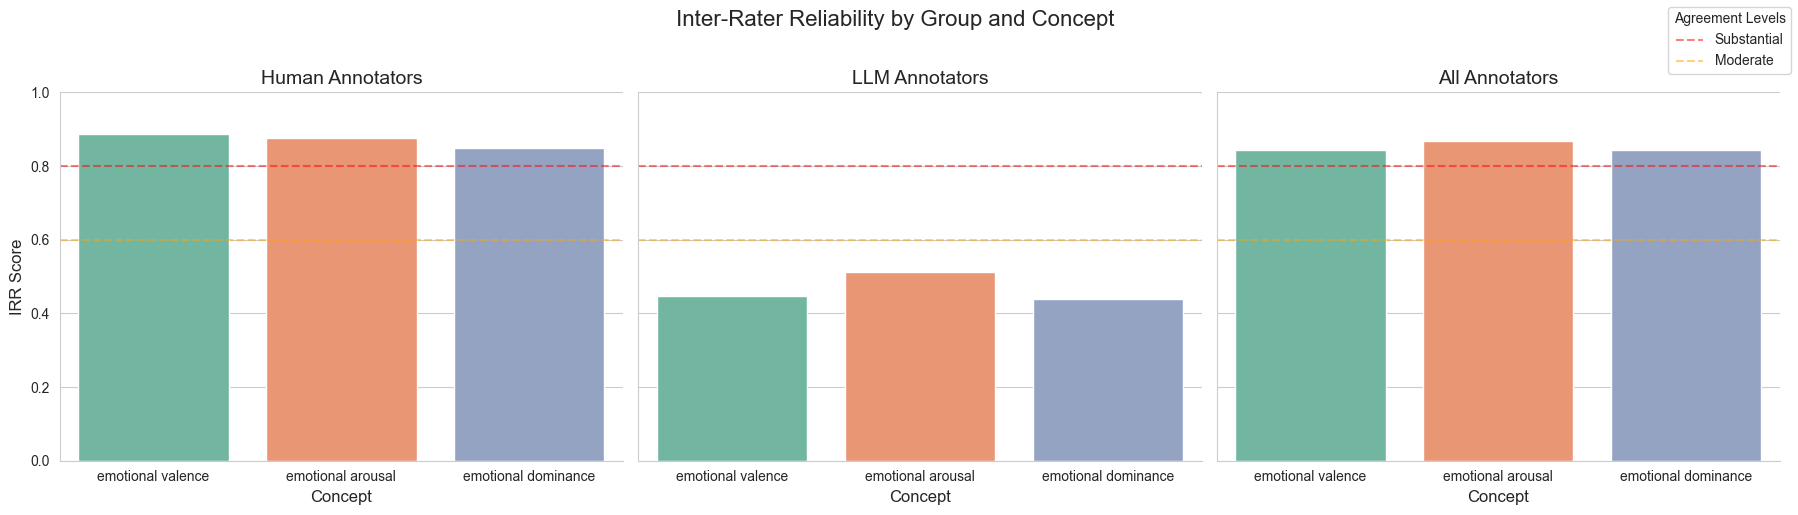

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

# Rename the groups for better readability
irr['group'] = irr['group'].replace({
    'human': 'Human Annotators',
    'llm': 'LLM Annotators',
    'all': 'All Annotators'
})

# Create a facet plot with separate subplots for each group
g = sns.catplot(
    data=irr,
    x='Concept',
    y='score',
    col='group',
    kind='bar',
    height=5,
    aspect=1.2,
    palette='Set2',
    hue='Concept',
    legend=False
)

# Customize the plot
g.set_axis_labels('Concept', 'IRR Score', fontsize=12)
g.set_titles(col_template='{col_name}', size=14)

# Add a horizontal line at different agreement thresholds
for ax in g.axes.flat:
    ax.axhline(y=0.8, color='red', linestyle='--', alpha=0.5, label='Substantial')
    ax.axhline(y=0.6, color='orange', linestyle='--', alpha=0.5, label='Moderate')
    ax.set_ylim(0, 1)

# Add caption for the horizontal lines
handles, labels = ax.get_legend_handles_labels()
handles += [plt.Line2D([0], [0], color='red', linestyle='--', alpha=0.5),
            plt.Line2D([0], [0], color='orange', linestyle='--', alpha=0.5)]
g._legend = g.fig.legend(handles, labels, title='Agreement Levels', loc='upper right', fontsize=10)

# Add overall title
plt.suptitle('Inter-Rater Reliability by Group and Concept', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

# Transitivity Check

In [19]:
p_val.check_transitivity()

{'A1': (0.8291457286432161, 34, 199),
 'A3': (0.9195979899497487, 16, 199),
 'A2': (0.9899497487437185, 2, 199),
 'A4': (0.9547738693467337, 9, 199),
 'decision_gpt-5': (0.9899497487437185, 2, 199),
 'decision_claude-sonnet-4-5-20250929': (0.8793969849246231, 24, 199)}

In [20]:
p_aro.check_transitivity()

{'A1': (0.8542713567839196, 29, 199),
 'A3': (0.8391959798994975, 32, 199),
 'A2': (0.9597989949748744, 8, 199),
 'A4': (0.9447236180904522, 11, 199),
 'decision_gpt-5': (0.914572864321608, 17, 199),
 'decision_claude-sonnet-4-5-20250929': (0.8391959798994975, 32, 199)}

In [21]:
p_dom.check_transitivity()

{'A1': (0.8743718592964824, 25, 199),
 'A3': (0.8994974874371859, 20, 199),
 'A2': (0.9547738693467337, 9, 199),
 'A4': (0.8442211055276382, 31, 199),
 'decision_gpt-5': (1.0, 0, 199),
 'decision_claude-sonnet-4-5-20250929': (0.9597989949748744, 8, 199)}

# Alt-Test

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 2 LLM decision columns: ['decision_gpt-5', 'decision_claude-sonnet-4-5-20250929']
Using LLM decision column: decision_gpt-5
Using LLM decision column: decision_gpt-5

ALT-TEST RESULTS - GPT-5
Winning Rate (ω): 0.000
Advantage Probability: 0.540
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5-20250929

ALT-TEST RESULTS - CLAUDE-SONNET-4-5-20250929
Winning Rate (ω): 0.000
Advantage Probability: 0.540
Tested against 4 human annotators

Testing all 2 LLM decision columns: ['decision_gpt-5', 'decision_claude-sonnet-4-5-20250929']
Using LLM decision column: decision_gpt-5
Using LLM decision column: decision_gpt-5

ALT-TEST RESULTS - GPT-5
Winning Rate (ω): 0.000
Advantage Probability: 0.540
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5-20250929

ALT-TEST RESULTS - CLAUDE-SONNET-4-5-20250929
Winning Rate (ω): 0.000
Advantage Probability: 0.540
Tested a

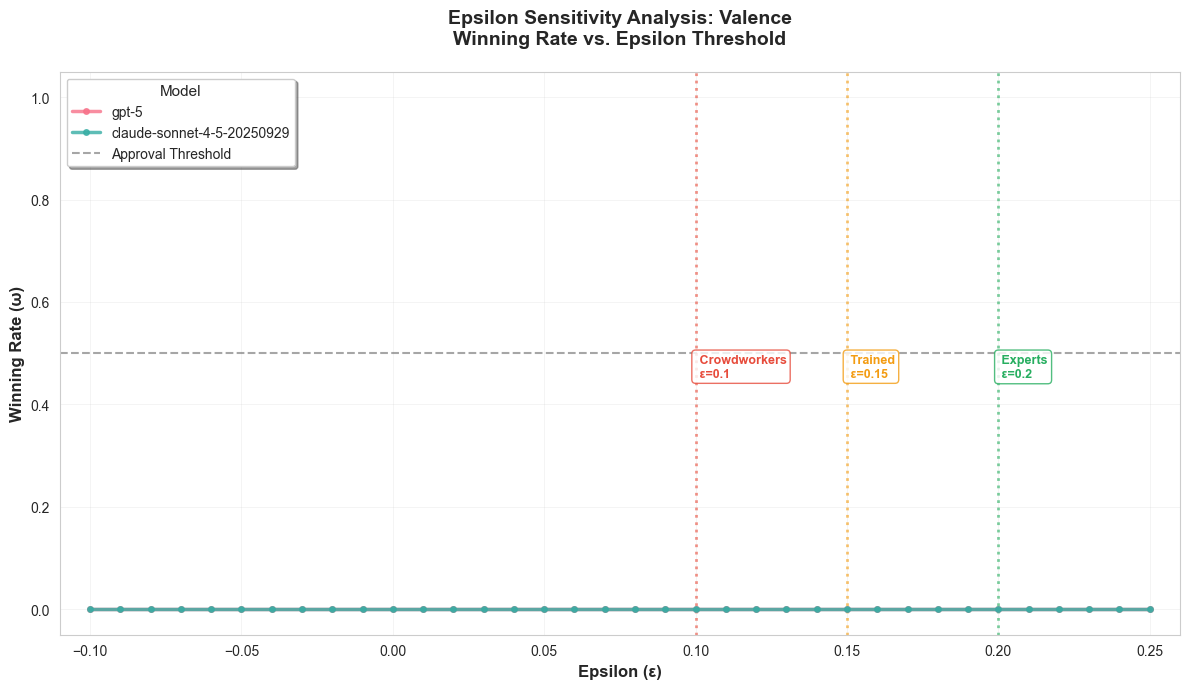

In [22]:
p_val.plot_epsilon_sensitivity()

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 2 LLM decision columns: ['decision_gpt-5', 'decision_claude-sonnet-4-5-20250929']
Using LLM decision column: decision_gpt-5
Using LLM decision column: decision_gpt-5

ALT-TEST RESULTS - GPT-5
Winning Rate (ω): 0.000
Advantage Probability: 0.785
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5-20250929

ALT-TEST RESULTS - CLAUDE-SONNET-4-5-20250929
Winning Rate (ω): 0.000
Advantage Probability: 0.730
Tested against 4 human annotators

Testing all 2 LLM decision columns: ['decision_gpt-5', 'decision_claude-sonnet-4-5-20250929']
Using LLM decision column: decision_gpt-5
Using LLM decision column: decision_gpt-5

ALT-TEST RESULTS - GPT-5
Winning Rate (ω): 0.000
Advantage Probability: 0.785
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5-20250929

ALT-TEST RESULTS - CLAUDE-SONNET-4-5-20250929
Winning Rate (ω): 0.000
Advantage Probability: 0.730
Tested a

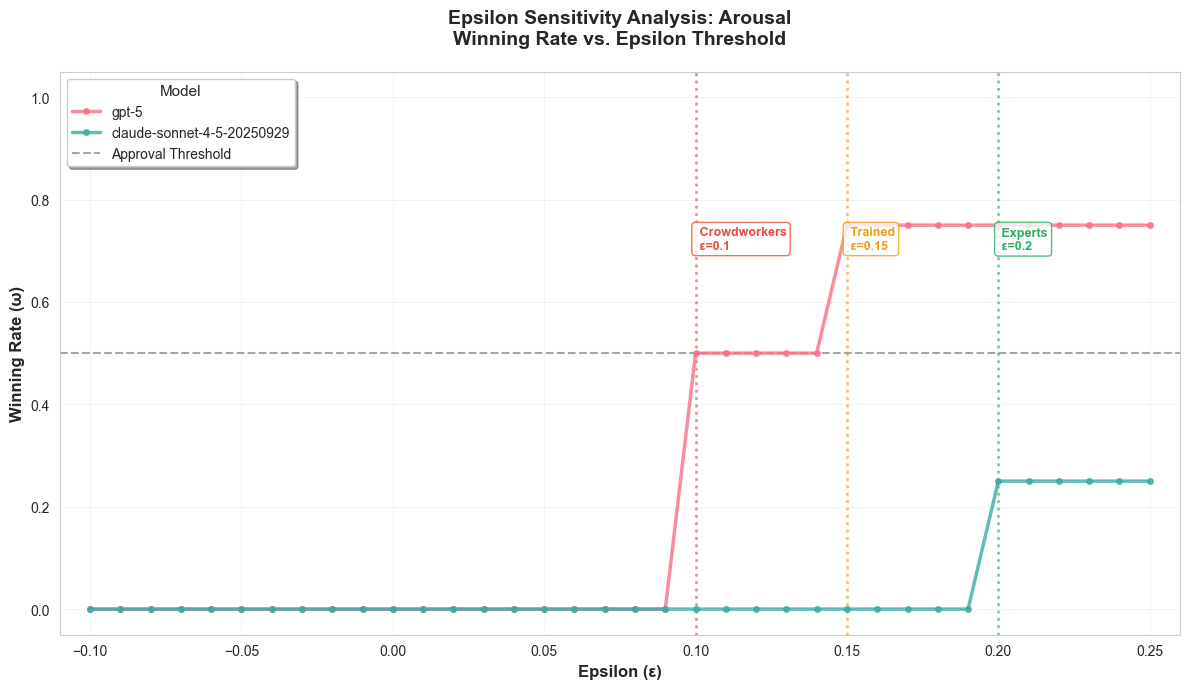

In [23]:
p_aro.plot_epsilon_sensitivity()

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 2 LLM decision columns: ['decision_gpt-5', 'decision_claude-sonnet-4-5-20250929']
Using LLM decision column: decision_gpt-5
Using LLM decision column: decision_gpt-5

ALT-TEST RESULTS - GPT-5
Winning Rate (ω): 0.000
Advantage Probability: 0.885
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5-20250929

ALT-TEST RESULTS - CLAUDE-SONNET-4-5-20250929
Winning Rate (ω): 0.000
Advantage Probability: 0.815
Tested against 4 human annotators

Testing all 2 LLM decision columns: ['decision_gpt-5', 'decision_claude-sonnet-4-5-20250929']
Using LLM decision column: decision_gpt-5
Using LLM decision column: decision_gpt-5

ALT-TEST RESULTS - GPT-5
Winning Rate (ω): 0.000
Advantage Probability: 0.885
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5-20250929

ALT-TEST RESULTS - CLAUDE-SONNET-4-5-20250929
Winning Rate (ω): 0.000
Advantage Probability: 0.815
Tested a

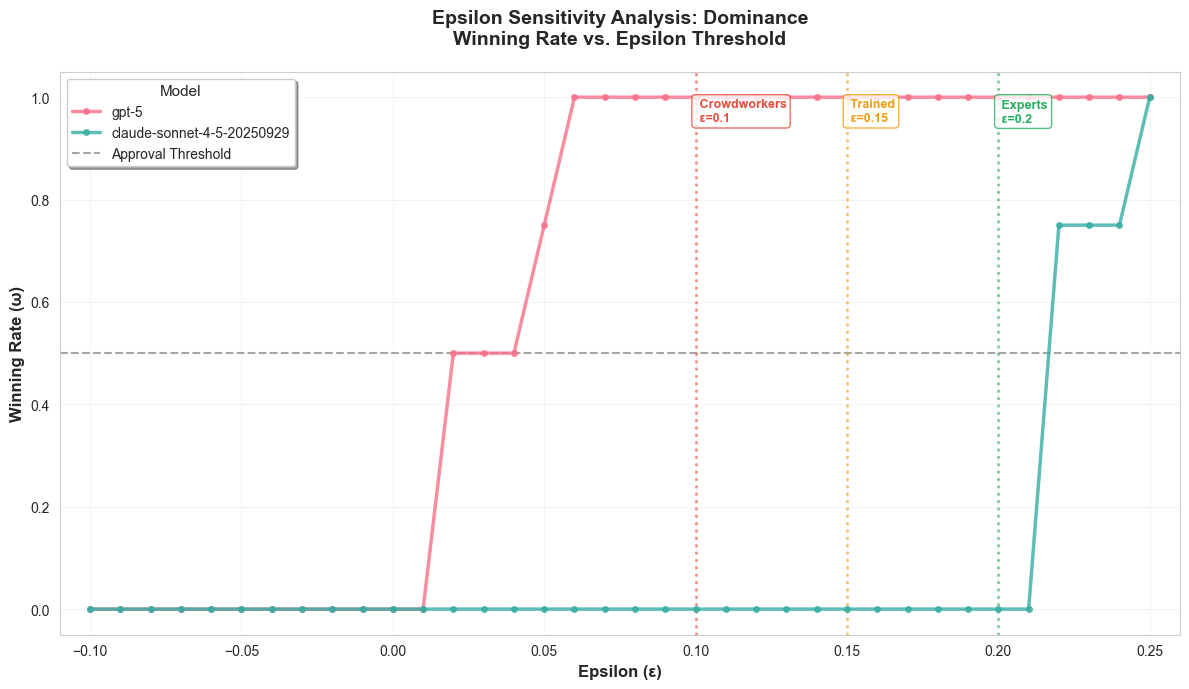

In [24]:
p_dom.plot_epsilon_sensitivity()

# Save pairadigms

In [25]:
p_val.save('Results/pairadigms/valence_pairadigm_11-6-25.pkl')
p_aro.save('Results/pairadigms/arousal_pairadigm_11-6-25.pkl')
p_dom.save('Results/pairadigms/dominance_pairadigm_11-6-25.pkl')

Pairadigm object saved successfully to: Results/pairadigms/valence_pairadigm_11-6-25.pkl
Pairadigm object saved successfully to: Results/pairadigms/arousal_pairadigm_11-6-25.pkl
Pairadigm object saved successfully to: Results/pairadigms/dominance_pairadigm_11-6-25.pkl


# Valence Alt-Test Failure Exploration

In [48]:
valence_df

,item1,item2,text1,text2,A1,Notes_A1,A3,Notes_A3,A2,Notes_A2,A4,Notes_A4
0,112C-L015_1504_1606,Italy_4868_4942,"It can help purchase clothing, school supplies...",have a happy vacation that place looks fascina...,Text2,,Text2,,Text2,,Text2,
1,112C-L015_1504_1606,NYTnewswire1_3167_3223,"It can help purchase clothing, school supplies...",I'm very excited we'll be on the same team for...,Text2,,Text2,,Text2,,Text2,
2,112C-L015_1504_1606,NYTnewswire2_7491_7738,"It can help purchase clothing, school supplies...","Also on Feb. 12, a week before the ice dancing...",Tie,,Text1,,Text1,,Text2,
3,112C-L015_1504_1606,Nathans_Bylichka_13402_13410,"It can help purchase clothing, school supplies...",“Bummer.,Text1,,Text1,,Text1,,Text1,
4,112C-L015_1504_1606,SemEval_185,"It can help purchase clothing, school supplies...",Squirrel jumps boy in park; rabies suspected,Text1,,Text1,,Text1,,Text1,
...,...,...,...,...,...,...,...,...,...,...,...,...
288,wsj_0120_2997_3087,captured_moments_33672_33739,"""The thing that will really break this market ...","He nodded, repeated, ""I am sorry,"" then slippe...",Text2,,Text1,,Text1,,Text1,
289,wsj_0120_2997_3087,captured_moments_35401_35418,"""The thing that will really break this market ...","Now she will be.""",Tie,,Tie,,Text1,,Text1,
290,wsj_0120_2997_3087,detroit_12015_12030,"""The thing that will really break this market ...","""Great Society""",Text2,,Text2,,Text2,,Text1,
291,wsj_0184_1749_1842,20020731-nyt_17990_18215,The company earlier this year adopted a shareh...,That was more evident here than in any other c...,Text2,,Text2,,Text2,,Text2,


In [86]:
p_val.pairwise_df

,item1,item2,text1,text2,A1,Notes_A1,A3,Notes_A3,A2,Notes_A2,A4,Notes_A4,breakdown1_gpt-5,breakdown2_gpt-5,breakdown1_claude-sonnet-4-5-20250929,breakdown2_claude-sonnet-4-5-20250929,decision_gpt-5,justification_gpt-5,decision_claude-sonnet-4-5-20250929,justification_claude-sonnet-4-5-20250929
0,112C-L015_1504_1606,Italy_4868_4942,"It can help purchase clothing, school supplies...",have a happy vacation that place looks fascina...,Text2,,Text2,,Text2,,Text2,,"Original Text: It can help purchase clothing, ...",Original Text: have a happy vacation that plac...,"Original Text: It can help purchase clothing, ...",Original Text: have a happy vacation that plac...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
1,112C-L015_1504_1606,NYTnewswire1_3167_3223,"It can help purchase clothing, school supplies...",I'm very excited we'll be on the same team for...,Text2,,Text2,,Text2,,Text2,,"Original Text: It can help purchase clothing, ...",Original Text: I'm very excited we'll be on th...,"Original Text: It can help purchase clothing, ...",Original Text: I'm very excited we'll be on th...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
2,112C-L015_1504_1606,NYTnewswire2_7491_7738,"It can help purchase clothing, school supplies...","Also on Feb. 12, a week before the ice dancing...",Tie,,Text1,,Text1,,Text2,,"Original Text: It can help purchase clothing, ...","Original Text: Also on Feb. 12, a week before ...","Original Text: It can help purchase clothing, ...","Original Text: Also on Feb. 12, a week before ...",Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
3,112C-L015_1504_1606,Nathans_Bylichka_13402_13410,"It can help purchase clothing, school supplies...",“Bummer.,Text1,,Text1,,Text1,,Text1,,"Original Text: It can help purchase clothing, ...",Original Text: “Bummer.\nPrompt 1 response: Th...,"Original Text: It can help purchase clothing, ...",Original Text: “Bummer.\nPrompt 1 response: Th...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: “B...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
4,112C-L015_1504_1606,SemEval_185,"It can help purchase clothing, school supplies...",Squirrel jumps boy in park; rabies suspected,Text1,,Text1,,Text1,,Text1,,"Original Text: It can help purchase clothing, ...",Original Text: Squirrel jumps boy in park; rab...,"Original Text: It can help purchase clothing, ...",Original Text: Squirrel jumps boy in park; rab...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: Th...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
288,wsj_0120_2997_3087,captured_moments_33672_33739,"""The thing that will really break this market ...","He nodded, repeated, ""I am sorry,"" then slippe...",Text2,,Text1,,Text1,,Text1,,"Original Text: ""The thing that will really bre...","Original Text: He nodded, repeated, ""I am sorr...","Original Text: ""The thing that will really bre...","Original Text: He nodded, repeated, ""I am sorr...",Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Tie,FINAL ANSWER: Tie\n\nJUSTIFICATION: Both descr...
289,wsj_0120_2997_3087,captured_moments_35401_35418,"""The thing that will really break this market ...","Now she will be.""",Tie,,Tie,,Text1,,Text1,,"Original Text: ""The thing that will really bre...","Original Text: Now she will be.""\nPrompt 1 res...","Original Text: ""The thing that will really bre...","Original Text: Now she will be.""\nPrompt 1 res...",Text1,FINAL ANSWER: Description 1\nJUSTIFICATION: De...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
290,wsj_0120_2997_3087,detroit_12015_12030,"""The thing that will really break this market ...","""Great Society""",Text2,,Text2,,Text2,,Text1,,"Original Text: ""The thing that will really bre...","Original Text: ""Great Society""\nPromp

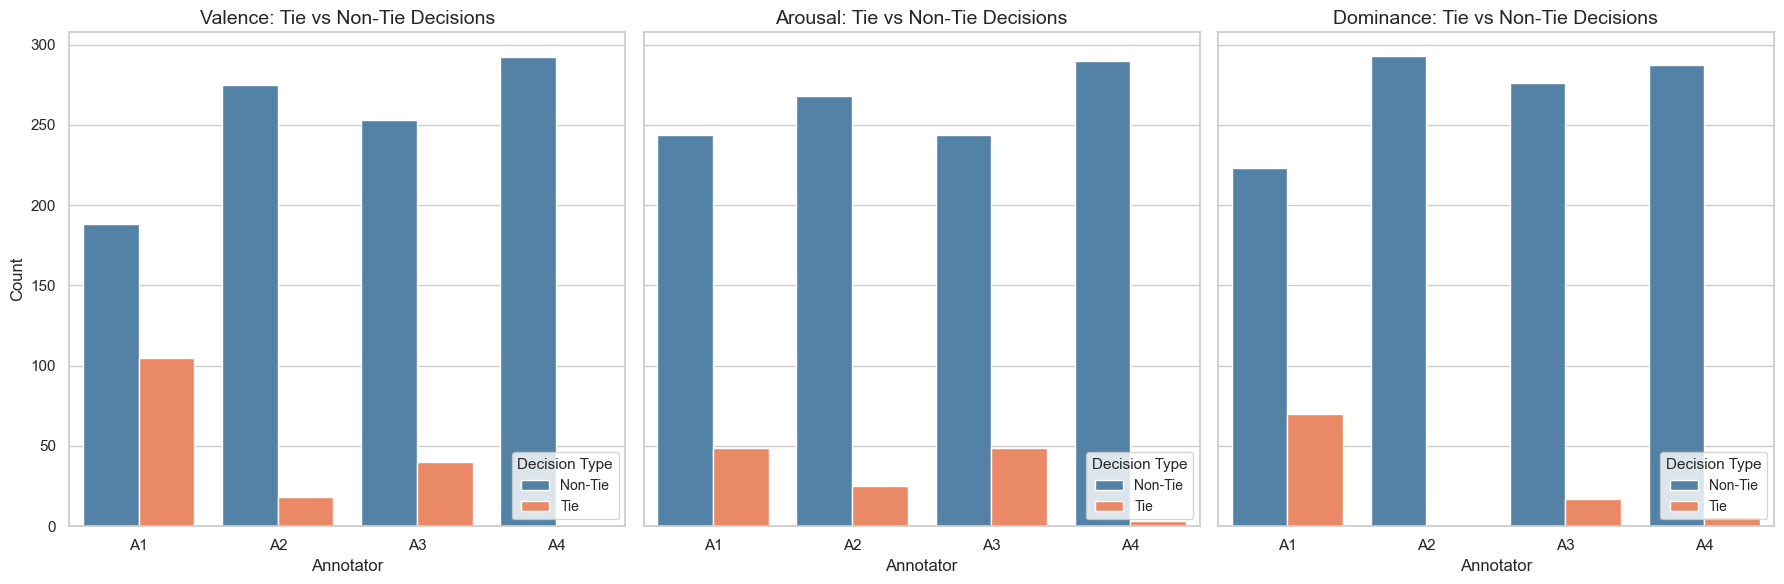


Summary of Tie Percentages:

Valence:
  A1: 105/293 (35.84%)
  A2: 18/293 (6.14%)
  A3: 40/293 (13.65%)
  A4: 1/293 (0.34%)

Arousal:
  A1: 49/293 (16.72%)
  A2: 25/293 (8.53%)
  A3: 49/293 (16.72%)
  A4: 3/293 (1.02%)

Dominance:
  A1: 70/293 (23.89%)
  A2: 0/293 (0.00%)
  A3: 17/293 (5.80%)
  A4: 6/293 (2.05%)



In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set Seaborn style
sns.set_theme(style="whitegrid")

# Create figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Define the dataframes and their names
dfs = [valence_df, arousal_df, dominance_df]
df_names = ['Valence', 'Arousal', 'Dominance']
annotators = ['A1', 'A2', 'A3', 'A4']

# For each concept
for idx, (df, name) in enumerate(zip(dfs, df_names)):
    tie_counts = []
    non_tie_counts = []
    
    # Count ties and non-ties for each annotator
    for annotator in annotators:
        tie_count = (df[annotator] == 'Tie').sum()
        non_tie_count = (df[annotator] != 'Tie').sum()
        tie_counts.append(tie_count)
        non_tie_counts.append(non_tie_count)
    
    # Create a DataFrame for plotting
    plot_data = pd.DataFrame({
        'Annotator': annotators * 2,
        'Count': non_tie_counts + tie_counts,
        'Type': ['Non-Tie'] * len(annotators) + ['Tie'] * len(annotators)
    })
    
    # Create stacked bar chart using Seaborn
    sns.barplot(
        data=plot_data,
        x='Annotator',
        y='Count',
        hue='Type',
        palette={'Non-Tie': 'steelblue', 'Tie': 'coral'},
        ax=axes[idx]
    )
    
    # Customize the subplot
    axes[idx].set_title(f'{name}: Tie vs Non-Tie Decisions', fontsize=14)
    axes[idx].set_xlabel('Annotator', fontsize=12)
    axes[idx].set_ylabel('Count', fontsize=12)
    axes[idx].legend(title='Decision Type', fontsize=10, title_fontsize=11, loc='lower right')
    
    # Add percentage labels
    # for i, annotator in enumerate(annotators):
    #     total = tie_counts[i] + non_tie_counts[i]
    #     tie_pct = (tie_counts[i] / total) * 100
    #     axes[idx].text(i, total + 5, f'{tie_pct:.1f}%', ha='center', va='bottom', fontsize=10)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

# Print summary statistics
print("\nSummary of Tie Percentages:\n")
for df, name in zip(dfs, df_names):
    print(f"{name}:")
    for annotator in annotators:
        tie_count = (df[annotator] == 'Tie').sum()
        total_count = len(df)
        tie_pct = (tie_count / total_count) * 100
        print(f"  {annotator}: {tie_count}/{total_count} ({tie_pct:.2f}%)")
    print()

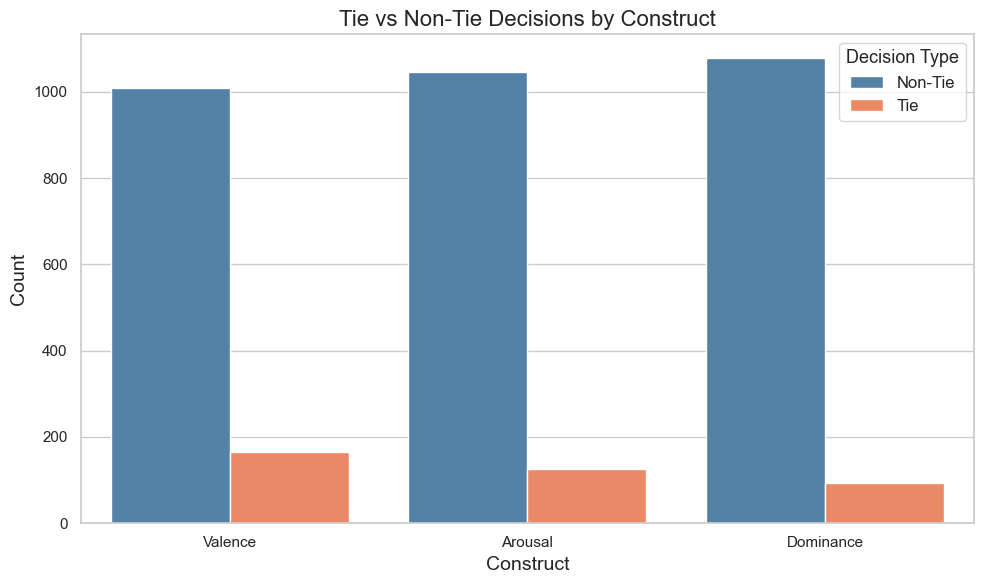


Summary of Tie Percentages by Construct:

Valence:
  Ties: 164/1172 (13.99%)
  Non-Ties: 1008/1172 (86.01%)

Arousal:
  Ties: 126/1172 (10.75%)
  Non-Ties: 1046/1172 (89.25%)

Dominance:
  Ties: 93/1172 (7.94%)
  Non-Ties: 1079/1172 (92.06%)



In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set Seaborn style
sns.set_theme(style="whitegrid")

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Define the dataframes and their names
dfs = [valence_df, arousal_df, dominance_df]
df_names = ['Valence', 'Arousal', 'Dominance']

# Initialize lists to store aggregated counts
constructs = []
tie_counts = []
non_tie_counts = []

# Aggregate data at the construct level
for df, name in zip(dfs, df_names):
    total_ties = 0
    total_non_ties = 0
    
    # Count ties and non-ties across all annotators
    for annotator in [col for col in df.columns if col.startswith('A')]:
        total_ties += (df[annotator] == 'Tie').sum()
        total_non_ties += (df[annotator] != 'Tie').sum()
    
    # Append to lists
    constructs.append(name)
    tie_counts.append(total_ties)
    non_tie_counts.append(total_non_ties)

# Create a DataFrame for plotting
plot_data = pd.DataFrame({
    'Construct': constructs * 2,
    'Count': non_tie_counts + tie_counts,
    'Type': ['Non-Tie'] * len(constructs) + ['Tie'] * len(constructs)
})

# Create a bar chart using Seaborn
sns.barplot(
    data=plot_data,
    x='Construct',
    y='Count',
    hue='Type',
    palette={'Non-Tie': 'steelblue', 'Tie': 'coral'},
    ax=ax
)

# Customize the plot
ax.set_title('Tie vs Non-Tie Decisions by Construct', fontsize=16)
ax.set_xlabel('Construct', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.legend(title='Decision Type', fontsize=12, title_fontsize=13)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

# Print summary statistics
print("\nSummary of Tie Percentages by Construct:\n")
for name, ties, non_ties in zip(constructs, tie_counts, non_tie_counts):
    total = ties + non_ties
    tie_pct = (ties / total) * 100
    non_tie_pct = (non_ties / total) * 100
    print(f"{name}:")
    print(f"  Ties: {ties}/{total} ({tie_pct:.2f}%)")
    print(f"  Non-Ties: {non_ties}/{total} ({non_tie_pct:.2f}%)\n")

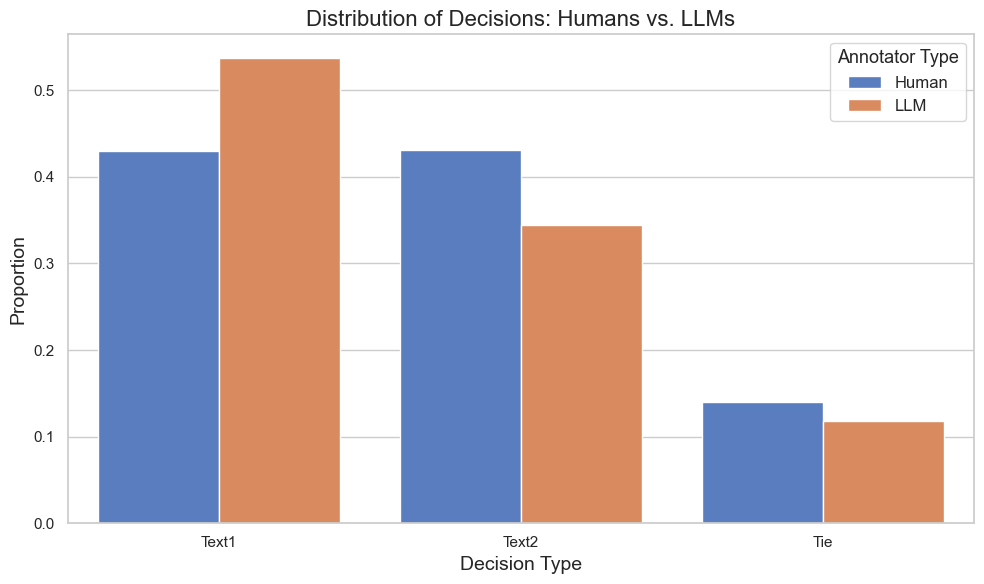


Summary of Decision Distributions:

Human:
  Text1: 503/1172 (42.92%)
  Text2: 505/1172 (43.09%)
  Tie: 164/1172 (13.99%)

LLM:
  Text1: 315/586 (53.75%)
  Text2: 202/586 (34.47%)
  Tie: 69/586 (11.77%)



In [88]:
from statsmodels.stats.proportion import proportions_ztest
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Define human and LLM annotators
human_annotators = [col for col in p_val.pairwise_df.columns if col.startswith('A')]
llm_annotators = [col for col in p_val.pairwise_df.columns if col.startswith('decision')]

# Initialize counts for each decision type
decision_types = ['Text1', 'Text2', 'Tie']
human_counts = {decision: 0 for decision in decision_types}
llm_counts = {decision: 0 for decision in decision_types}

# Count occurrences of each decision type for humans
for decision in decision_types:
    human_counts[decision] = (p_val.pairwise_df[human_annotators] == decision).sum().sum()

# Count occurrences of each decision type for LLMs
for decision in decision_types:
    llm_counts[decision] = (p_val.pairwise_df[llm_annotators] == decision).sum().sum()

# Combine counts into a DataFrame for plotting
plot_data = pd.DataFrame({
    'Decision': decision_types * 2,
    'Count': [human_counts[decision] for decision in decision_types] +
             [llm_counts[decision] for decision in decision_types],
    'Annotator Type': ['Human'] * len(decision_types) + ['LLM'] * len(decision_types)
})

# Normalize the counts to proportions
total_human = sum(human_counts.values())
total_llm = sum(llm_counts.values())
plot_data.loc[plot_data['Annotator Type'] == 'Human', 'Proportion'] = plot_data.loc[plot_data['Annotator Type'] == 'Human', 'Count'] / total_human
plot_data.loc[plot_data['Annotator Type'] == 'LLM', 'Proportion'] = plot_data.loc[plot_data['Annotator Type'] == 'LLM', 'Count'] / total_llm

# Plot the distributions
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data, x='Decision', y='Proportion', hue='Annotator Type', palette='muted')
plt.title('Distribution of Decisions: Humans vs. LLMs', fontsize=16)
plt.xlabel('Decision Type', fontsize=14)
plt.ylabel('Proportion', fontsize=14)
plt.legend(title='Annotator Type', fontsize=12, title_fontsize=13)
plt.tight_layout()
plt.show()

# Print summary statistics
print("\nSummary of Decision Distributions:\n")
for annotator_type, counts in zip(['Human', 'LLM'], [human_counts, llm_counts]):
    total = sum(counts.values())
    print(f"{annotator_type}:")
    for decision, count in counts.items():
        percentage = (count / total) * 100
        print(f"  {decision}: {count}/{total} ({percentage:.2f}%)")
    print()

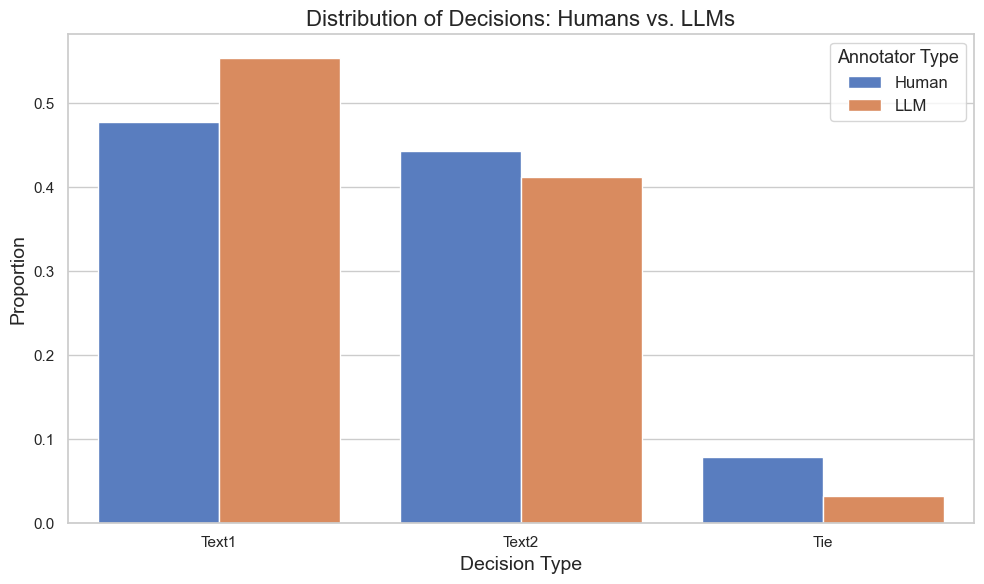


Summary of Decision Distributions:

Human:
  Text1: 560/1172 (47.78%)
  Text2: 519/1172 (44.28%)
  Tie: 93/1172 (7.94%)

LLM:
  Text1: 325/586 (55.46%)
  Text2: 242/586 (41.30%)
  Tie: 19/586 (3.24%)



In [89]:
from statsmodels.stats.proportion import proportions_ztest
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Define human and LLM annotators
human_annotators = [col for col in p_dom.pairwise_df.columns if col.startswith('A')]
llm_annotators = [col for col in p_dom.pairwise_df.columns if col.startswith('decision')]

# Initialize counts for each decision type
decision_types = ['Text1', 'Text2', 'Tie']
human_counts = {decision: 0 for decision in decision_types}
llm_counts = {decision: 0 for decision in decision_types}

# Count occurrences of each decision type for humans
for decision in decision_types:
    human_counts[decision] = (p_dom.pairwise_df[human_annotators] == decision).sum().sum()

# Count occurrences of each decision type for LLMs
for decision in decision_types:
    llm_counts[decision] = (p_dom.pairwise_df[llm_annotators] == decision).sum().sum()

# Combine counts into a DataFrame for plotting
plot_data = pd.DataFrame({
    'Decision': decision_types * 2,
    'Count': [human_counts[decision] for decision in decision_types] +
             [llm_counts[decision] for decision in decision_types],
    'Annotator Type': ['Human'] * len(decision_types) + ['LLM'] * len(decision_types)
})

# Normalize the counts to proportions
total_human = sum(human_counts.values())
total_llm = sum(llm_counts.values())
plot_data.loc[plot_data['Annotator Type'] == 'Human', 'Proportion'] = plot_data.loc[plot_data['Annotator Type'] == 'Human', 'Count'] / total_human
plot_data.loc[plot_data['Annotator Type'] == 'LLM', 'Proportion'] = plot_data.loc[plot_data['Annotator Type'] == 'LLM', 'Count'] / total_llm

# Plot the distributions
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data, x='Decision', y='Proportion', hue='Annotator Type', palette='muted')
plt.title('Distribution of Decisions: Humans vs. LLMs', fontsize=16)
plt.xlabel('Decision Type', fontsize=14)
plt.ylabel('Proportion', fontsize=14)
plt.legend(title='Annotator Type', fontsize=12, title_fontsize=13)
plt.tight_layout()
plt.show()

# Print summary statistics
print("\nSummary of Decision Distributions:\n")
for annotator_type, counts in zip(['Human', 'LLM'], [human_counts, llm_counts]):
    total = sum(counts.values())
    print(f"{annotator_type}:")
    for decision, count in counts.items():
        percentage = (count / total) * 100
        print(f"  {decision}: {count}/{total} ({percentage:.2f}%)")
    print()

In [60]:
p_val.pairwise_df

,item1,item2,text1,text2,A1,Notes_A1,A3,Notes_A3,A2,Notes_A2,A4,Notes_A4,breakdown1_gpt-5,breakdown2_gpt-5,breakdown1_claude-sonnet-4-5-20250929,breakdown2_claude-sonnet-4-5-20250929,decision_gpt-5,justification_gpt-5,decision_claude-sonnet-4-5-20250929,justification_claude-sonnet-4-5-20250929
0,112C-L015_1504_1606,Italy_4868_4942,"It can help purchase clothing, school supplies...",have a happy vacation that place looks fascina...,Text2,,Text2,,Text2,,Text2,,"Original Text: It can help purchase clothing, ...",Original Text: have a happy vacation that plac...,"Original Text: It can help purchase clothing, ...",Original Text: have a happy vacation that plac...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
1,112C-L015_1504_1606,NYTnewswire1_3167_3223,"It can help purchase clothing, school supplies...",I'm very excited we'll be on the same team for...,Text2,,Text2,,Text2,,Text2,,"Original Text: It can help purchase clothing, ...",Original Text: I'm very excited we'll be on th...,"Original Text: It can help purchase clothing, ...",Original Text: I'm very excited we'll be on th...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
2,112C-L015_1504_1606,NYTnewswire2_7491_7738,"It can help purchase clothing, school supplies...","Also on Feb. 12, a week before the ice dancing...",Tie,,Text1,,Text1,,Text2,,"Original Text: It can help purchase clothing, ...","Original Text: Also on Feb. 12, a week before ...","Original Text: It can help purchase clothing, ...","Original Text: Also on Feb. 12, a week before ...",Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
3,112C-L015_1504_1606,Nathans_Bylichka_13402_13410,"It can help purchase clothing, school supplies...",“Bummer.,Text1,,Text1,,Text1,,Text1,,"Original Text: It can help purchase clothing, ...",Original Text: “Bummer.\nPrompt 1 response: Th...,"Original Text: It can help purchase clothing, ...",Original Text: “Bummer.\nPrompt 1 response: Th...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: “B...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
4,112C-L015_1504_1606,SemEval_185,"It can help purchase clothing, school supplies...",Squirrel jumps boy in park; rabies suspected,Text1,,Text1,,Text1,,Text1,,"Original Text: It can help purchase clothing, ...",Original Text: Squirrel jumps boy in park; rab...,"Original Text: It can help purchase clothing, ...",Original Text: Squirrel jumps boy in park; rab...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: Th...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
288,wsj_0120_2997_3087,captured_moments_33672_33739,"""The thing that will really break this market ...","He nodded, repeated, ""I am sorry,"" then slippe...",Text2,,Text1,,Text1,,Text1,,"Original Text: ""The thing that will really bre...","Original Text: He nodded, repeated, ""I am sorr...","Original Text: ""The thing that will really bre...","Original Text: He nodded, repeated, ""I am sorr...",Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: It...,Tie,FINAL ANSWER: Tie\n\nJUSTIFICATION: Both descr...
289,wsj_0120_2997_3087,captured_moments_35401_35418,"""The thing that will really break this market ...","Now she will be.""",Tie,,Tie,,Text1,,Text1,,"Original Text: ""The thing that will really bre...","Original Text: Now she will be.""\nPrompt 1 res...","Original Text: ""The thing that will really bre...","Original Text: Now she will be.""\nPrompt 1 res...",Text1,FINAL ANSWER: Description 1\nJUSTIFICATION: De...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
290,wsj_0120_2997_3087,detroit_12015_12030,"""The thing that will really break this market ...","""Great Society""",Text2,,Text2,,Text2,,Text1,,"Original Text: ""The thing that will really bre...","Original Text: ""Great Society""\nPromp

In [62]:
from statsmodels.stats.proportion import proportions_ztest
import pandas as pd

# Define human and LLM annotators
human_annotators = [col for col in p_val.pairwise_df.columns if col.startswith('A')]
llm_annotators = [col for col in p_val.pairwise_df.columns if col.startswith('decision')]

# Calculate "Tie" counts and total counts for humans
human_tie_counts = sum((p_val.pairwise_df[human_annotators] == 'Tie').sum())
human_total_counts = len(p_val.pairwise_df) * len(human_annotators)

# Calculate "Tie" counts and total counts for LLMs
llm_tie_counts = sum((p_val.pairwise_df[llm_annotators] == 'Tie').sum())
llm_total_counts = len(p_val.pairwise_df) * len(llm_annotators)

# Combine counts
tie_counts = [human_tie_counts, llm_tie_counts]
total_counts = [human_total_counts, llm_total_counts]

# Perform a two-sample z-test for proportions
stat, p_value = proportions_ztest(tie_counts, total_counts)

# Print results
print(f"Z-statistic: {stat:.3f}")
print(f"P-value: {p_value:.3f}")

if p_value < 0.05:
    print("Significant difference in 'Tie' usage between humans and LLMs.")
else:
    print("No significant difference in 'Tie' usage between humans and LLMs.")

Z-statistic: 1.293
P-value: 0.196
No significant difference in 'Tie' usage between humans and LLMs.
